# Pauli-String Time Evolution: Circuit Synthesis, Trotterization, and Control Errors

This project began with a simple question: **how do we turn a Pauli-generated unitary into an actual quantum circuit?**

I first worked through single-qubit examples using $H$, $S$, $S^\dagger$, and $R_Z$, then used CNOTs to extend the construction to multi-qubit Pauli operators. After checking one nontrivial example explicitly, I generalized the pattern to an arbitrary Pauli string


$$P=P_{n-1}\otimes\cdots\otimes P_0,\qquad P_j\in\{I,X,Y,Z\}$$

and built a reusable circuit for

$$
U_P(\theta)=e^{-i\theta P}.
$$

The second part of the project uses this primitive to simulate Hamiltonians written as sums of Pauli strings,

$$
H=\sum_\alpha c_\alpha P_\alpha,
$$

with a first-order product formula. I compare the circuit to exact matrix evolution on small systems, study circuit resources as the Pauli weight grows, and finally add systematic and random rotation errors to see how increasing the number of Trotter steps trades approximation error against imperfect gates.

### Roadmap

1. Start from elementary single-qubit rotations.
2. Build multi-qubit Pauli exponentials with basis changes and parity accumulation.
3. Generalize to arbitrary Pauli strings and validate edge cases.
4. Analyze gate count and depth versus Pauli weight.
5. Use the Pauli primitive to Trotterize $H=aX+bZ$.
6. Generalize to arbitrary sparse Pauli-sum Hamiltonians.
7. Compare ideal, coherent-overrotation, and random-overrotation simulations.

## 0. Defining Colors and Plotting Style

In [1]:
import matplotlib.pyplot as plt

BLUE = "#070090"
GREEN = "#3A8424"
RED = "#8E1B11"
GOLD = "#8C6A00"

plt.rcParams.update(
    {
        "font.family": "STIXGeneral",
        "mathtext.fontset": "stix",
        "font.size": 13,
        "axes.labelsize": 16,
        "axes.titlesize": 16,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "legend.fontsize": 12,
    }
)

CIRCUIT_STYLE = {
    "name": "textbook",
    "backgroundcolor": "#FFFFFF",
    "linecolor": "#333333",
    "creglinecolor": "#777777",
    "gatetextcolor": "#FFFFFF",
    "fontsize": 13,
    "subfontsize": 10,
    "displaycolor": {
        "h": (BLUE, "#FFFFFF"),
        "cx": (GREEN, "#FFFFFF"),
        "rz": (RED, "#FFFFFF"),
        "s": (GOLD, "#FFFFFF"),
        "sdg": (GOLD, "#FFFFFF"),
    },
}


def draw_styled_circuit(circuit, title):
    """Draw a circuit using the plotting style shared across the notebook."""
    fig = circuit.draw(
        "mpl",
        style=CIRCUIT_STYLE,
        scale=0.9,
        fold=-1,
    )
    fig.patch.set_facecolor("white")
    fig.suptitle(
        title,
        fontsize=16,
        fontfamily="STIXGeneral",
        y=0.98,
    )
    fig.subplots_adjust(
        top=0.80,
        bottom=0.10,
        left=0.05,
        right=0.98,
    )
    return fig

## 1. Setup and conventions

Qiskit labels qubit $0$ with the **rightmost** character of a Pauli string. For example,

$$
\texttt{"XIY"} = X_2\otimes I_1\otimes Y_0.
$$

I use this convention consistently both in the circuit construction and in `qiskit.quantum_info.Pauli`.

The circuit basis used in the Pauli-string construction is the one requested in the project: $H$, $S$, $S^\dagger$, $R_Z$, and $CX$.

In [2]:
import numpy as np
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Pauli

from pauli_hamiltonian_evolution import (
    exact_ax_bz,
    exact_pauli_evolution,
    normalized_frobenius_error,
    pauli_evolution,
    pauli_evolution_coherent,
    pauli_evolution_random,
    pauli_sum_exact,
    pauli_sum_trotter,
    pauli_sum_trotter_circuit,
    trotter_ax_bz_circuit,
)

## 2. Starting simple: a single-qubit Pauli rotation

For any Pauli matrix $P$,

$$
P^2=I,
$$

so its exponential has the closed form

$$
e^{-i\theta P}=\cos\theta\,I-i\sin\theta\,P.
$$

Qiskit's $R_Z$ gate satisfies

$$
R_Z(\phi)=e^{-i\phi Z/2},
$$

therefore

$$
e^{-i\theta Z}=R_Z(2\theta).
$$

To generate $X$ or $Y$ rotations, I first rotate that Pauli operator into the $Z$ basis, apply the $Z$ rotation, and undo the basis change:

$$
X \xrightarrow{H} Z,
\qquad
Y \xrightarrow{S^\dagger,\;H} Z.
$$

The following was my first explicit check, for $e^{-i\theta Y}$.

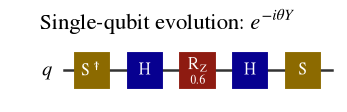

In [3]:
theta = 0.3

qc_y = QuantumCircuit(1)
qc_y.sdg(0)
qc_y.h(0)
qc_y.rz(2 * theta, 0)
qc_y.h(0)
qc_y.s(0)

display(
    draw_styled_circuit(
        qc_y,
        r"Single-qubit evolution: $e^{-i\theta Y}$",
    )
)

In [4]:
Y = Pauli("Y").to_matrix()
expected_y = np.cos(theta) * np.eye(2) - 1j * np.sin(theta) * Y
actual_y = Operator(qc_y).data

print("Matches exact e^{-i theta Y}:", np.allclose(actual_y, expected_y))

Matches exact e^{-i theta Y}: True


## 3. Multi-qubit Pauli strings: the parity construction

For a $Z$-type string, the eigenvalue is determined by the parity of the participating qubits. CNOTs can accumulate that parity onto one target qubit. I then apply a single $R_Z(2\theta)$ to the target and reverse the CNOTs.

For example,

$$
e^{-i\theta Z_1Z_0}
$$

is implemented by

$$
\mathrm{CX}_{0\to1}\;R_Z(2\theta)_1\;\mathrm{CX}_{0\to1}.
$$

The same idea works for longer strings. Non-$Z$ Paulis are first changed into the $Z$ basis. We set $\theta = 0.3$.

ZZ example correct: True


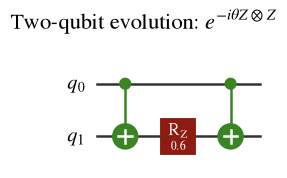

In [5]:
qc_zz = QuantumCircuit(2)
qc_zz.cx(0, 1)
qc_zz.rz(2 * theta, 1)
qc_zz.cx(0, 1)

expected_zz = np.cos(theta) * np.eye(4) - 1j * np.sin(theta) * Pauli("ZZ").to_matrix()

print("ZZ example correct:", np.allclose(Operator(qc_zz).data, expected_zz))

display(
    draw_styled_circuit(
        qc_zz,
        r"Two-qubit evolution: $e^{-i\theta Z\otimes Z}$",
    )
)

### A nontrivial example before generalizing

I next combined both ideas in

$$
P=X_2\otimes I_1\otimes Y_0,
$$
represented by the Qiskit string `XIY`.

The $X$ and $Y$ factors are rotated into the $Z$ basis, the parity is accumulated across the active qubits, one $R_Z$ rotation applies the phase, and all operations are uncomputed.

XIY example correct: True


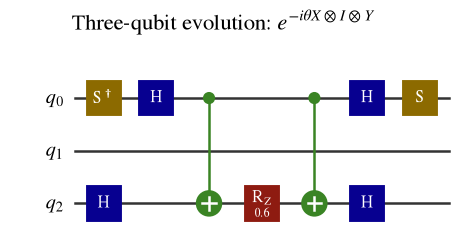

In [6]:
qc_xiy = QuantumCircuit(3)

# Y on q0 -> Z basis
qc_xiy.sdg(0)
qc_xiy.h(0)

# X on q2 -> Z basis
qc_xiy.h(2)

# Accumulate parity on q2, rotate, and uncompute
qc_xiy.cx(0, 2)
qc_xiy.rz(2 * theta, 2)
qc_xiy.cx(0, 2)

# Undo basis changes
qc_xiy.h(0)
qc_xiy.s(0)
qc_xiy.h(2)

P_xiy = Pauli("XIY").to_matrix()
expected_xiy = np.cos(theta) * np.eye(8) - 1j * np.sin(theta) * P_xiy

print("XIY example correct:", np.allclose(Operator(qc_xiy).data, expected_xiy))
display(
    draw_styled_circuit(
        qc_xiy,
        r"Three-qubit evolution: $e^{-i\theta X\otimes I\otimes Y}$",
    )
)

The examples reveal the general recipe:

1. Ignore identity factors.
2. Rotate every active $X$ or $Y$ factor into the $Z$ basis.
3. Use CX gates to accumulate the parity of all active qubits onto one target.
4. Apply $R_Z(2\theta)$ to that target.
5. Reverse the $CX$ ladder.
6. Undo the basis changes.

This leads directly to a circuit for an arbitrary Pauli string.

### Generalizing the construction

The hand-built examples suggest a reusable algorithm. For each non-identity Pauli factor, rotate into the $Z$ basis; accumulate the parity of all active qubits on one target; apply $R_Z(2\theta)$; uncompute the parity; and undo the basis changes. The special case $P=I^{\otimes n}$ contributes only the global phase $e^{-i\theta}$.

The reusable implementation is kept in `src/pauli_hamiltonian_evolution/evolution.py` and imported above as `pauli_evolution`. Keeping the implementation in the package makes the notebook a narrative and experiment layer rather than a second copy of the source code.


## 4. Validation and edge cases

Because $P^2=I$, every Pauli-string exponential can be checked independently against

$$
U_{\rm exact}=\cos\theta\,I-i\sin\theta\,P.
$$

The tests below include $Y$ factors, intervening identities, a single active factor, the all-identity string, zero angle, and negative angle.

In [7]:
validation_cases = [
    ("Y", 0.3),
    ("XIY", 0.3),
    ("XIZYI", 0.2),
    ("IIZII", 0.4),
    ("III", 0.3),
    ("X", 0.0),
    ("YZ", -0.4),
]

for pauli_string, angle in validation_cases:
    circuit = pauli_evolution(pauli_string, angle)
    actual = Operator(circuit).data
    expected = exact_pauli_evolution(pauli_string, angle)
    assert np.allclose(actual, expected, atol=1e-12)
    print(f"{pauli_string:>5s}, theta={angle:>5.2f}: passed")

    Y, theta= 0.30: passed
  XIY, theta= 0.30: passed


XIZYI, theta= 0.20: passed
IIZII, theta= 0.40: passed
  III, theta= 0.30: passed
    X, theta= 0.00: passed
   YZ, theta=-0.40: passed


## 5. Resource analysis

Let the Pauli weight be

$$
w=\left|\{j:P_j\neq I\}\right|.
$$

For the construction above, the entangling-gate cost depends only on the number of active qubits:

$$
N_{\rm CX}=2(w-1),\qquad w\ge 1.
$$

There is one $R_Z$ gate. Basis changes add

$$
2n_X+4n_Y
$$

single-qubit gates, where $n_X$ and $n_Y$ are the numbers of $X$ and $Y$ factors. Therefore

$$
N_{\rm gates}
=
2(w-1)+1+2n_X+4n_Y.
$$

The CX cost is thus linear in Pauli weight. The total gate count and depth are also linear, with different constant overheads depending on whether the string contains $X$, $Y$, or only $Z$.

To isolate the dependence on $w$, the experiment below keeps the register width fixed at 10 qubits and varies only the number of non-identity factors.

In [8]:
max_weight = 10
weights = np.arange(1, max_weight + 1)

resources = {"X": [], "Y": [], "Z": []}

for letter in resources:
    for weight in weights:
        pauli_string = "I" * (max_weight - weight) + letter * weight
        circuit = pauli_evolution(pauli_string, theta=0.3)
        counts = circuit.count_ops()

        resources[letter].append(
            {
                "weight": weight,
                "total_gates": circuit.size(),
                "cx": counts.get("cx", 0),
                "depth": circuit.depth(),
            }
        )

# The CX formula should be independent of the Pauli letters.
for letter in resources:
    measured_cx = np.array([row["cx"] for row in resources[letter]])
    expected_cx = 2 * (weights - 1)
    assert np.array_equal(measured_cx, expected_cx)

print("CX scaling check passed: N_CX = 2(w - 1).")

CX scaling check passed: N_CX = 2(w - 1).


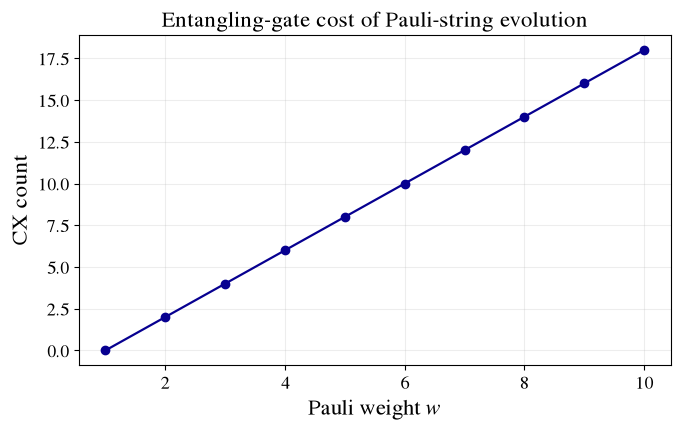

In [9]:
plt.figure(figsize=(7, 4.5))

plt.plot(
    weights,
    2 * (weights - 1),
    marker="o",
    color=BLUE,
    lw=1.6,
    ms=6,
)

plt.xlabel(r"Pauli weight $w$")
plt.ylabel("CX count")
plt.title("Entangling-gate cost of Pauli-string evolution")

plt.grid(True, alpha=0.22)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

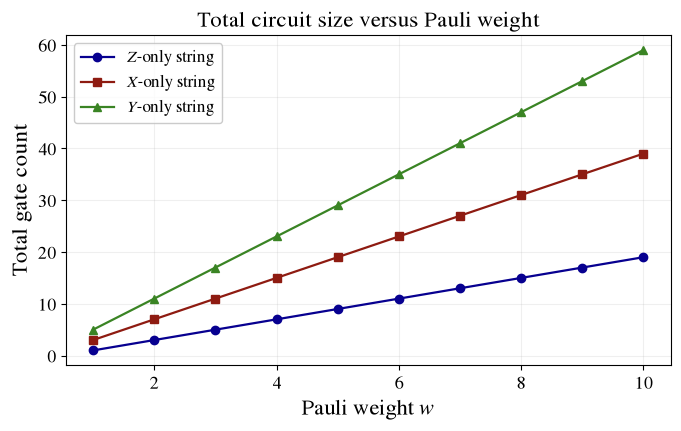

In [10]:
plt.figure(figsize=(7, 4.5))

colors = {
    "Z": BLUE,
    "X": RED,
    "Y": GREEN,
}

markers = {
    "Z": "o",
    "X": "s",
    "Y": "^",
}

for letter in ["Z", "X", "Y"]:
    total = [row["total_gates"] for row in resources[letter]]

    plt.plot(
        weights,
        total,
        marker=markers[letter],
        color=colors[letter],
        linewidth=1.6,
        markersize=6,
        label=rf"${letter}$-only string",
    )

plt.xlabel(r"Pauli weight $w$")
plt.ylabel("Total gate count")
plt.title("Total circuit size versus Pauli weight")

plt.legend(
    frameon=True,
    facecolor="white",
    edgecolor="0.75",
)

plt.grid(True, alpha=0.20)

# Keep the full box
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

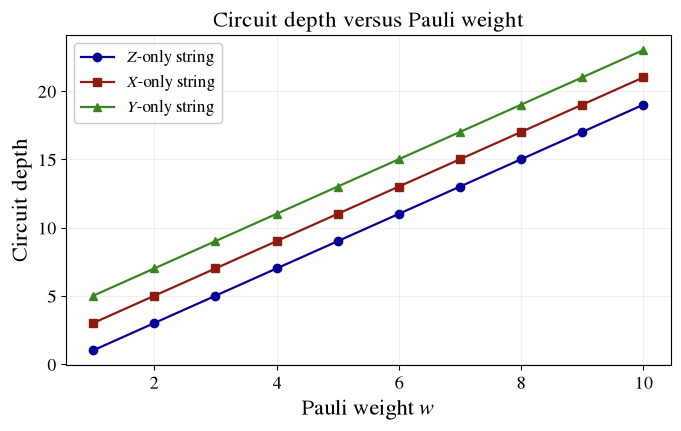

In [11]:
plt.figure(figsize=(7, 4.5))

colors = {
    "Z": BLUE,
    "X": RED,
    "Y": GREEN,
}

markers = {
    "Z": "o",
    "X": "s",
    "Y": "^",
}

for letter in ["Z", "X", "Y"]:
    depth = [row["depth"] for row in resources[letter]]

    plt.plot(
        weights,
        depth,
        marker=markers[letter],
        color=colors[letter],
        linewidth=1.6,
        markersize=6,
        label=rf"${letter}$-only string",
    )

plt.xlabel(r"Pauli weight $w$")
plt.ylabel("Circuit depth")
plt.title("Circuit depth versus Pauli weight")

plt.legend(
    frameon=True,
    facecolor="white",
    edgecolor="0.75",
)

plt.grid(True, alpha=0.20)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

The resource plots separate two effects. The CX ladder is controlled entirely by the Pauli weight, while $X$ and $ Y$ factors require additional basis-change gates. In this all-to-all connectivity model, the construction therefore has $O(w)$ gate count and $O(w)$ depth. Hardware connectivity constraints could add routing overhead, which is not included here.

## 6. From a single Pauli string to $H=aX+bZ$

The next step is to simulate a Hamiltonian containing **noncommuting** Pauli terms,

$$
H=aX+bZ.
$$

Because $X$ and $Z$ anticommute,

$$
H^2=(a^2+b^2)I.
$$

Defining

$$
\omega=\sqrt{a^2+b^2},
$$

the exact evolution is

$$
e^{-itH}
=
\cos(\omega t)I
-i\sin(\omega t)\frac{aX+bZ}{\omega}.
$$

A first-order product formula with $r$ steps and $\Delta t=t/r$ is

$$
U_r(t)
=
\left[
e^{-ibZ\Delta t}
e^{-iaX\Delta t}
\right]^r.
$$

The order above matches the circuit convention below: the $X$ rotation is appended first and therefore acts first on the state.

For the first Hamiltonian example we use

$$H=aX+bZ. $$

Because $X$ and $Z$ do not commute, the exact exponential cannot be split into two independent exponentials. The small-system exact reference `exact_ax_bz` and the first-order circuit builder `trotter_ax_bz_circuit` are implemented in the package and imported above. The normalized Frobenius error is

$$E=\frac{\lVert U_{\rm approx}-U_{\rm exact}\rVert_F}{\sqrt{2^n}}.$$


In [12]:
a, b, time = 0.7, 0.4, 1.0
step_counts = np.array([1, 2, 5, 10, 20, 50, 100])

exact_unitary = exact_ax_bz(a, b, time)
simple_errors = []

for steps in step_counts:
    approximate = Operator(trotter_ax_bz_circuit(a, b, time, int(steps))).data
    simple_errors.append(normalized_frobenius_error(approximate, exact_unitary))

print("steps:", step_counts.tolist())
print("normalized Frobenius errors:", simple_errors)

steps: [1, 2, 5, 10, 20, 50, 100]
normalized Frobenius errors: [0.2604132867372494, 0.12653694661034579, 0.05020531203782131, 0.02507346487430896, 0.012533084775170837, 0.005012825407796392, 0.00250638352580835]


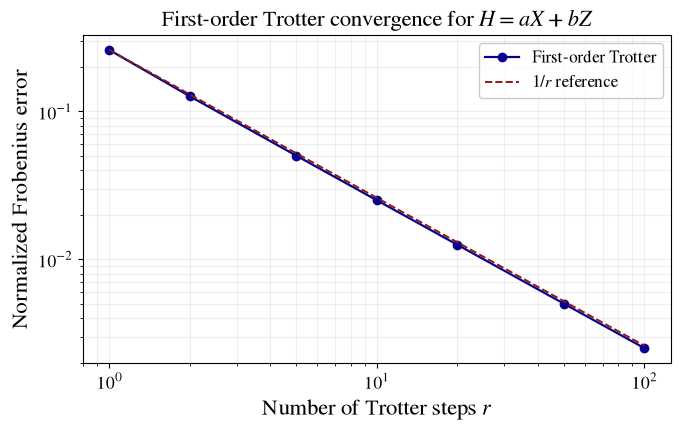

In [13]:
plt.figure(figsize=(7, 4.5))

plt.loglog(
    step_counts,
    simple_errors,
    marker="o",
    color=BLUE,
    linewidth=1.6,
    markersize=6,
    label="First-order Trotter",
)

# A 1/r reference line, normalized to the first data point
reference = simple_errors[0] / step_counts

plt.loglog(
    step_counts,
    reference,
    linestyle="--",
    color=RED,
    linewidth=1.4,
    label=r"$1/r$ reference",
)

plt.xlabel(r"Number of Trotter steps $r$")
plt.ylabel("Normalized Frobenius error")
plt.title(r"First-order Trotter convergence for $H=aX+bZ$")

plt.legend(
    frameon=True,
    facecolor="white",
    edgecolor="0.75",
)

plt.grid(True, which="both", alpha=0.20)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

For fixed total time, first-order product-formula error is expected to decrease as the Trotter step size decreases. The simple $aX+bZ$ model is useful because the exact unitary is known analytically, so the circuit can be checked without relying on another circuit-synthesis routine.

## 7. Generalization to arbitrary sparse Pauli Hamiltonians

The same construction does not depend on the particular choice $aX+bZ$. Any $n$-qubit Hamiltonian can be expanded in the Pauli basis,

$$
H=\sum_\alpha c_\alpha P_\alpha.
$$

For a sparse or local Hamiltonian, the number of nonzero terms can remain manageable. I represent the Hamiltonian as either an ordered mapping or an iterable of

$$
(\text{Pauli string},\text{coefficient})
$$

pairs.

For one Trotter slice,

$$
e^{-iH\Delta t}
\approx
\prod_\alpha e^{-ic_\alpha P_\alpha\Delta t},
$$

and every factor on the right is already implemented by `pauli_evolution`.

### A model-independent Pauli-sum compiler

We now represent a sparse $n$-qubit Hamiltonian as

$$H=\sum_\alpha c_\alpha P_\alpha,$$

where each $P_\alpha$ is an equal-length Pauli string. The package functions `pauli_sum_exact`, `pauli_sum_trotter_circuit`, and `pauli_sum_trotter` validate the input, build the dense exact reference for small systems, and compile the first-order product formula

$$U_r(t)=\left[\prod_\alpha e^{-ic_\alpha P_\alpha t/r}\right]^r.$$

The order of terms is the insertion order of the mapping (or the supplied order of an iterable of pairs). Identity strings are retained so their global phase is not silently discarded.


### Sanity checks: one term, commuting terms, noncommuting terms

We validate the construction above for three cases:

- one Pauli term: product formula should be exact;
- multiple commuting terms: product formula should still be exact;
- noncommuting terms: error should decrease as the number of Trotter steps increases.

In [14]:
single_term = {"X": 0.7}
commuting_terms = {"ZI": 0.7, "ZZ": 0.4}
noncommuting_terms = {
    "XI": 0.7,
    "ZZ": 0.4,
    "IY": -0.2,
}

time = 1.0

for label, terms in [
    ("single term", single_term),
    ("commuting terms", commuting_terms),
]:
    exact_unitary = pauli_sum_exact(terms, time)

    for steps in [1, 2, 5, 10]:
        approximate = pauli_sum_trotter(terms, time, steps)
        error = normalized_frobenius_error(approximate, exact_unitary)
        assert error < 1e-12

    print(f"{label}: exact to numerical precision")

exact_noncommuting = pauli_sum_exact(noncommuting_terms, time)
general_step_counts = np.array([1, 2, 5, 10, 20, 50])
general_errors = []

for steps in general_step_counts:
    approximate = pauli_sum_trotter(noncommuting_terms, time, int(steps))
    general_errors.append(normalized_frobenius_error(approximate, exact_noncommuting))

assert general_errors[-1] < general_errors[0]
print("noncommuting terms: error decreases with more Trotter steps")

single term: exact to numerical precision
commuting terms: exact to numerical precision
noncommuting terms: error decreases with more Trotter steps


We now define the code for the single, commuting, and noncommuting Hamiltonians. Then we will draw the exact circuits for each case.

In [15]:
single_circuit = pauli_sum_trotter_circuit(
    single_term,
    time,
    steps=1,
)

commuting_circuit = pauli_sum_trotter_circuit(
    commuting_terms,
    time,
    steps=1,
)

noncommuting_circuit = pauli_sum_trotter_circuit(
    noncommuting_terms,
    time,
    steps=1,
)

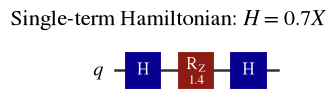

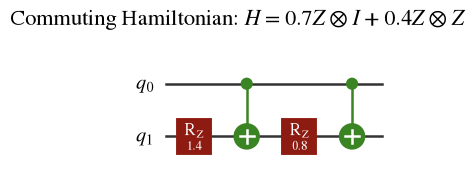

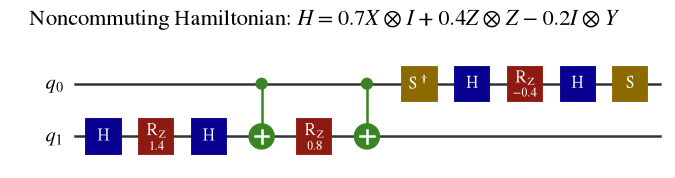

In [16]:
single_title = r"Single-term Hamiltonian: $H=0.7X$"
commuting_title = (
    r"Commuting Hamiltonian: "
    r"$H=0.7Z\otimes I+0.4Z\otimes Z$"
)
noncommuting_title = (
    r"Noncommuting Hamiltonian: "
    r"$H=0.7X\otimes I+0.4Z\otimes Z-0.2I\otimes Y$"
)

display(draw_styled_circuit(single_circuit, single_title))
display(draw_styled_circuit(commuting_circuit, commuting_title))
display(draw_styled_circuit(noncommuting_circuit, noncommuting_title))

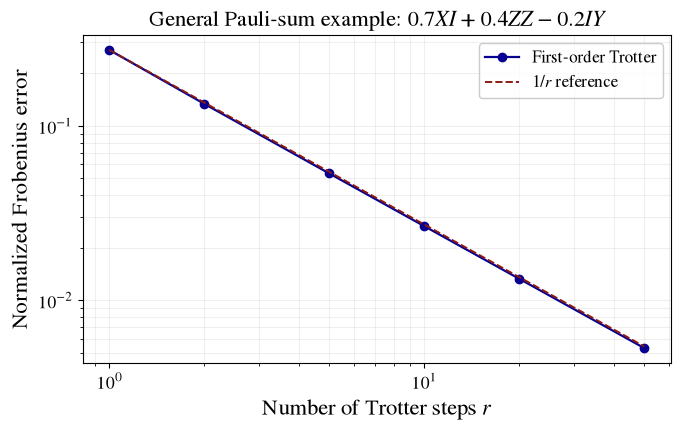

In [17]:
plt.figure(figsize=(7, 4.5))

plt.loglog(
    general_step_counts,
    general_errors,
    marker="o",
    color=BLUE,
    linewidth=1.6,
    markersize=6,
    label="First-order Trotter",
)

general_reference = general_errors[0] / general_step_counts
plt.loglog(
    general_step_counts,
    general_reference,
    linestyle="--",
    color=RED,
    linewidth=1.4,
    label=r"$1/r$ reference",
)

plt.xlabel(r"Number of Trotter steps $r$")
plt.ylabel("Normalized Frobenius error")
plt.title(r"General Pauli-sum example: $0.7XI+0.4ZZ-0.2IY$")
plt.legend(frameon=True, facecolor="white", edgecolor="0.75")
plt.grid(True, which="both", alpha=0.20)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

This is the main generalization of the project: the circuit builder no longer knows anything about the physical model. It only needs a list of Pauli terms and coefficients. The dense `expm` calculation is used only as a small-system classical reference; it is not part of the quantum simulation algorithm.

## 8. Systematic and random control errors

More Trotter steps reduce the ideal product-formula error, but they also require more gates. To explore this competition, I perturb the physical $R_Z$ angle used inside every Pauli exponential.

The ideal gate is

$$
R_Z(2\theta).
$$

For a **systematic overrotation**, I use

$$
R_Z(2\theta+\epsilon),
$$

where the same $\epsilon$ is added to every Pauli rotation.

For a **random overrotation**, I instead use

$$
R_Z(2\theta+\delta),\qquad
\delta\sim\mathcal N(0,\sigma^2),
$$

with an independent draw for each Pauli rotation.

These are control-error models, not a general stochastic quantum channel. In particular, every individual random realization is still unitary.

The final experiment perturbs the physical $R_Z$ angle used in each Pauli exponential. We compare a fixed additive overrotation $\epsilon$ with independent Gaussian angle errors $\delta\sim\mathcal{N}(0,\sigma)$. These are control-error models for otherwise unitary circuit realizations, not general stochastic quantum channels. The corresponding builders are implemented in `src/pauli_hamiltonian_evolution/evolution.py` and imported as `pauli_evolution_coherent` and `pauli_evolution_random`.


We now plot the errors in implementing the circuit versus Trotter steps for three cases : 
1. no errors, 
2. a systematic overrotation, and 
3. a stochastic error. 

With ideal case, we should see errors go down as Trotter step size $r$ increases, for the systematic overrotation case, we should see errors decrease at first but the errors in the imperfect gates add up, and 3. a partial cancellation from the stochastic errors partially canceling.

In [18]:
epsilon = 0.01
sigma = 0.01
noise_step_counts = np.array([1, 2, 5, 10, 20, 50, 100])
n_trials = 50

exact_unitary = pauli_sum_exact(noncommuting_terms, time)

ideal_errors = []
coherent_errors = []
random_mean_errors = []
random_std_errors = []

rng = np.random.default_rng(42)

for steps in noise_step_counts:
    steps = int(steps)

    ideal = pauli_sum_trotter(
        noncommuting_terms,
        time,
        steps,
    )
    ideal_errors.append(normalized_frobenius_error(ideal, exact_unitary))

    coherent = pauli_sum_trotter(
        noncommuting_terms,
        time,
        steps,
        evolution=pauli_evolution_coherent,
        epsilon=epsilon,
    )
    coherent_errors.append(normalized_frobenius_error(coherent, exact_unitary))

    trial_errors = []
    for _ in range(n_trials):
        random_unitary = pauli_sum_trotter(
            noncommuting_terms,
            time,
            steps,
            evolution=pauli_evolution_random,
            sigma=sigma,
            rng=rng,
        )
        trial_errors.append(normalized_frobenius_error(random_unitary, exact_unitary))

    random_mean_errors.append(np.mean(trial_errors))
    random_std_errors.append(np.std(trial_errors))

Here we finally plot the results of the noisy Trotter simulations. The ideal Trotter error decreases with more steps, while the overrotation and random stochatic errors eventually dominate for large step counts.

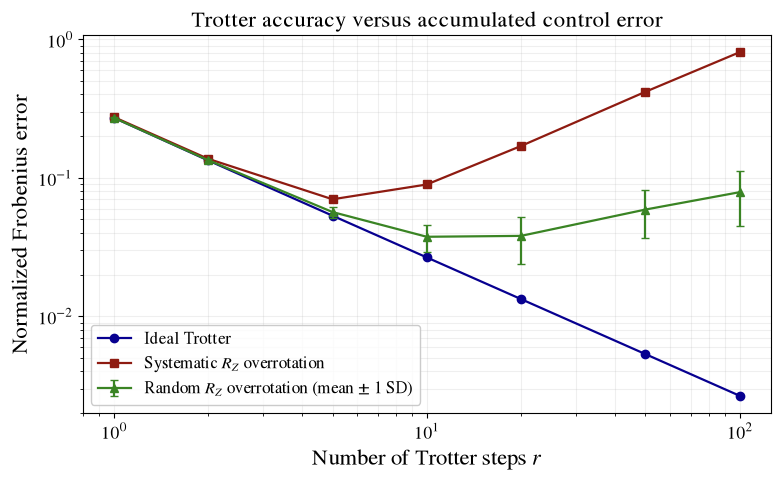

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    noise_step_counts,
    ideal_errors,
    marker="o",
    color=BLUE,
    linewidth=1.6,
    markersize=6,
    label="Ideal Trotter",
)

plt.plot(
    noise_step_counts,
    coherent_errors,
    marker="s",
    color=RED,
    linewidth=1.6,
    markersize=6,
    label=r"Systematic $R_Z$ overrotation",
)

plt.errorbar(
    noise_step_counts,
    random_mean_errors,
    yerr=random_std_errors,
    fmt="^-",
    color=GREEN,
    ecolor=GREEN,
    linewidth=1.6,
    markersize=6,
    capsize=3,
    label=r"Random $R_Z$ overrotation (mean $\pm$ 1 SD)",
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"Number of Trotter steps $r$")
plt.ylabel("Normalized Frobenius error")
plt.title("Trotter accuracy versus accumulated control error")

plt.legend(
    frameon=True,
    facecolor="white",
    edgecolor="0.75",
)

plt.grid(True, which="both", alpha=0.20)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

The ideal curve isolates product-formula error, which scales as $1/r$ in the number of Trotter steps $r$. The red and green curves include an additional error source that is applied every time a Pauli exponential is implemented. This exposes the central tradeoff: making $\Delta t$ smaller improves the mathematical Trotter approximation, but increasing $r$ also increases the number of imperfect gates.

The systematic and random models need not accumulate in the same way. A fixed rotation error (red curve) can add coherently across repeated gates, while independent zero-mean fluctuations (green curve) partially average over realizations. The numerical curves show how that competition appears for this particular Hamiltonian and error scale.

## 9. Conclusions

We have used primitive gate identities to implement Hamiltonians with sums of arbitrary Pauli strings.
- A Pauli exponential $e^{-i\theta P}$ can be implemented using basis changes, a CX parity ladder, one $R_Z$, and uncomputation.
- The entangling-gate cost is
 $$
  N_{\rm CX}=2(w-1),
$$
  so this construction scales linearly with Pauli weight $w$.
For the Hamiltonian
$$
  H=\sum_\alpha c_\alpha P_\alpha
$$
  we use first-order product Trotter formula to implement unitary Hamiltonian evolution in terms of elementary gates.
- Single-term and commuting Hamiltonians provide exact sanity checks, while noncommuting Hamiltonians show the expected convergence as the number of Trotter steps increases.
- Adding systematic or random rotation errors shows why circuit accuracy is not determined by Trotter error alone: deeper product formulas can accumulate more physical control error.

### Limitations

The exact matrix exponential used here for validation scales exponentially with qubit number, so it is only a small-system benchmark. The error model changes rotation angles but does not include decoherence, leakage, measurement error, or a full noisy-channel model. 

### Possible extensions

Natural next steps include higher-order Suzuki product formulas, modeling realistic noise channels, and encoding the simulated dynamics in a small quantum error-correcting code.

## References and implementation notes

- The Erdős Institute, *Quantum Computing Bootcamp: Mini-project 1*, Project 10 (Pauli-string time evolution).
- Qiskit objects used here: `QuantumCircuit`, `Operator`, and `Pauli`.
- All circuit constructions in the notebook are assembled explicitly from elementary gates; dense matrix exponentiation is used only to check how well the trotterization works.